# Notebook Básico:   
## Entrenamiento de 2 Modelos y Comparación de Escalamiento 
***Autor:*** Giovanni Cabrera

Construir un flujo sencillo de Machine Learning en Python para entrenar dos modelos básicos: un modelo de **Regresión Lineal** (para predecir un valor numérico) y uno de **Regresión Logística** (para predecir una categoría de Sí/No) Observaremos de forma guiada y práctica cómo afecta aplicar **escalamiento de datos** antes de entrenar

## Librerías y carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#import seaborn as sns
from sklearn.preprocessing import LabelEncoder

df_salarios = pd.read_csv("data\salaries.csv")
df_mfg = pd.read_csv("data\MFG10YearTerminationData.csv")

In [2]:
df_salarios.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2025,SE,FT,Data Product Owner,170000,USD,170000,US,0,US,M
1,2025,SE,FT,Data Product Owner,110000,USD,110000,US,0,US,M
2,2025,SE,FT,Data Product Owner,170000,USD,170000,US,0,US,M
3,2025,SE,FT,Data Product Owner,110000,USD,110000,US,0,US,M
4,2025,SE,FT,Engineer,143000,USD,143000,US,0,US,M


In [3]:
df_mfg.head()

,EmployeeID,recorddate_key,birthdate_key,orighiredate_key,terminationdate_key,age,length_of_service,city_name,department_name,job_title,store_name,gender_short,gender_full,termreason_desc,termtype_desc,STATUS_YEAR,STATUS,BUSINESS_UNIT
0,1318,12/31/2006 0:00,1/3/1954,8/28/1989,1/1/1900,52,17,Vancouver,Executive,CEO,35,M,Male,Not Applicable,Not Applicable,2006,ACTIVE,HEADOFFICE
1,1318,12/31/2007 0:00,1/3/1954,8/28/1989,1/1/1900,53,18,Vancouver,Executive,CEO,35,M,Male,Not Applicable,Not Applicable,2007,ACTIVE,HEADOFFICE
2,1318,12/31/2008 0:00,1/3/1954,8/28/1989,1/1/1900,54,19,Vancouver,Executive,CEO,35,M,Male,Not Applicable,Not Applicable,2008,ACTIVE,HEADOFFICE
3,1318,12/31/2009 0:00,1/3/1954,8/28/1989,1/1/1900,55,20,Vancouver,Executive,CEO,35,M,Male,Not Applicable,Not Applicable,2009,ACTIVE,HEADOFFICE
4,1318,12/31/2010 0:00,1/3/1954,8/28/1989,1/1/1900,56,21,Vancouver,Executive,CEO,35,M,Male,Not Applicable,Not Applicable,2010,ACTIVE,HEADOFFICE


In [4]:
df_salarios.info()

<class 'pandas.DataFrame'>
RangeIndex: 73148 entries, 0 to 73147
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   work_year           73148 non-null  int64
 1   experience_level    73148 non-null  str  
 2   employment_type     73148 non-null  str  
 3   job_title           73148 non-null  str  
 4   salary              73148 non-null  int64
 5   salary_currency     73148 non-null  str  
 6   salary_in_usd       73148 non-null  int64
 7   employee_residence  73148 non-null  str  
 8   remote_ratio        73148 non-null  int64
 9   company_location    73148 non-null  str  
 10  company_size        73148 non-null  str  
dtypes: int64(4), str(7)
memory usage: 6.1 MB


In [5]:
df_mfg.info()

<class 'pandas.DataFrame'>
RangeIndex: 49653 entries, 0 to 49652
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   EmployeeID           49653 non-null  int64
 1   recorddate_key       49653 non-null  str  
 2   birthdate_key        49653 non-null  str  
 3   orighiredate_key     49653 non-null  str  
 4   terminationdate_key  49653 non-null  str  
 5   age                  49653 non-null  int64
 6   length_of_service    49653 non-null  int64
 7   city_name            49653 non-null  str  
 8   department_name      49653 non-null  str  
 9   job_title            49653 non-null  str  
 10  store_name           49653 non-null  int64
 11  gender_short         49653 non-null  str  
 12  gender_full          49653 non-null  str  
 13  termreason_desc      49653 non-null  str  
 14  termtype_desc        49653 non-null  str  
 15  STATUS_YEAR          49653 non-null  int64
 16  STATUS               49653 non-nu

### Detección y eliminación de duplicados

In [6]:
df_salarios = df_salarios.drop_duplicates(keep="last")
duplicados_salarios = df_salarios.duplicated().sum()
print(f"Registros duplicados df_salarios: {duplicados_salarios}")

Registros duplicados df_salarios: 0


In [7]:
df_mfg = df_mfg.drop_duplicates(subset=["EmployeeID","STATUS_YEAR"], keep="last")
duplicados_mfg = df_mfg.duplicated(subset=["EmployeeID","STATUS_YEAR"]).sum()
print(f"Registros duplicados df_mfg: {duplicados_mfg}")

Registros duplicados df_mfg: 0


## Modelo 1 - Regresión Lineal (Salary Prediction)

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

df_reg = df_salarios.copy()

# Variables categóricas a numéricas
for col in df_reg.columns:
    if df_reg[col].dtype == "str":
        df_reg[col] = LabelEncoder().fit_transform(df_reg[col])

X_reg = df_reg.drop(
    ["salary", "salary_in_usd"],
    axis=1
)

y_reg = df_reg["salary_in_usd"]

print(X_reg.shape)

(34024, 9)


### División Train/Test

In [9]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

### Regresión Lineal SIN Escalamiento

In [10]:
from sklearn.linear_model import LinearRegression

modelo_reg = LinearRegression()

modelo_reg.fit(
    X_train_reg,
    y_train_reg
)

pred_reg = modelo_reg.predict(
    X_test_reg
)

### Métricas

In [11]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


mae = mean_absolute_error(
    y_test_reg,
    pred_reg
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_reg,
        pred_reg
    )
)

r2 = r2_score(
    y_test_reg,
    pred_reg
)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 51290.163086030676
RMSE: 68769.3739481856
R2: 0.1759114972329413


### Regresión Lineal CON Escalamiento

In [12]:
from sklearn.preprocessing import StandardScaler

scaler_reg = StandardScaler()

X_train_reg_scaled = scaler_reg.fit_transform(
    X_train_reg
)

X_test_reg_scaled = scaler_reg.transform(
    X_test_reg
)

In [13]:
modelo_reg_scaled = LinearRegression()

modelo_reg_scaled.fit(
    X_train_reg_scaled,
    y_train_reg
)

pred_reg_scaled = modelo_reg_scaled.predict(
    X_test_reg_scaled
)

In [14]:
mae_scaled = mean_absolute_error(
    y_test_reg,
    pred_reg_scaled
)

rmse_scaled = np.sqrt(
    mean_squared_error(
        y_test_reg,
        pred_reg_scaled
    )
)

r2_scaled = r2_score(
    y_test_reg,
    pred_reg_scaled
)

print("MAE:", mae_scaled)
print("RMSE:", rmse_scaled)
print("R2:", r2_scaled)

MAE: 51290.163086030494
RMSE: 68769.3739481856
R2: 0.17591149723294142


## Conclusión: Efecto del Escalamiento en la Regresión Lineal

Al comparar los resultados del modelo de Regresión Lineal antes y después de aplicar **StandardScaler**, se observa que las métricas obtenidas son prácticamente idénticas:

- MAE ≈ 51,290
- RMSE ≈ 68,769
- R² ≈ 0.176

Esto indica que el escalamiento de las variables no produjo una mejora significativa en el desempeño del modelo. Este comportamiento es esperado en la Regresión Lineal, ya que el algoritmo no depende de distancias entre observaciones y, en la mayoría de los casos, genera predicciones equivalentes independientemente de la escala de las variables.

Por otra parte, el valor de **R² = 0.176** indica que el modelo explica aproximadamente el **17.6% de la variabilidad del salario**, por lo que aún existe una gran proporción de información que no está siendo capturada por las variables incluidas en el entrenamiento.

En conclusión, para este dataset el escalamiento no generó cambios relevantes en la capacidad predictiva de la Regresión Lineal. Las posibles mejoras deberían centrarse en la selección de variables más representativas, la ingeniería de características y la evaluación de modelos más complejos que puedan capturar relaciones no lineales entre las variables y el salario.

### Gráfico de dispersión y línea de predicción

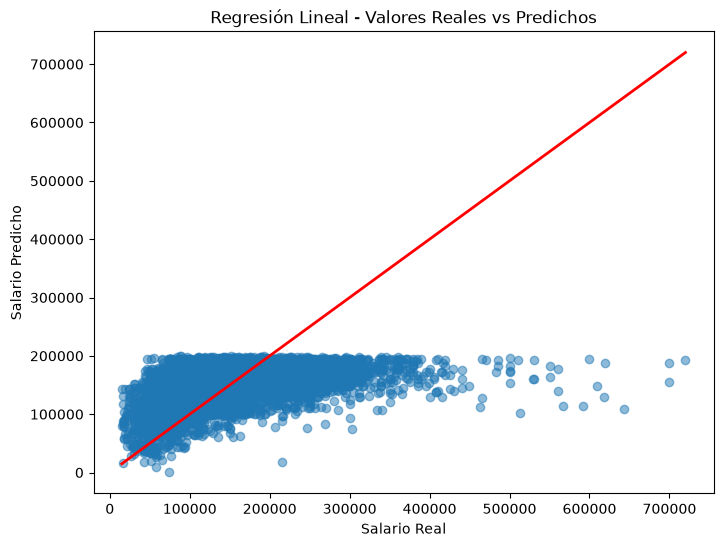

In [15]:
plt.figure(figsize=(8,6))

plt.scatter(
    y_test_reg,
    pred_reg,
    alpha=0.5
)

plt.plot(
    [y_test_reg.min(), y_test_reg.max()],
    [y_test_reg.min(), y_test_reg.max()],
    color="red",
    linewidth=2
)

plt.xlabel("Salario Real")
plt.ylabel("Salario Predicho")
plt.title("Regresión Lineal - Valores Reales vs Predichos")

plt.show()

### Interpretación

Cada punto representa una observación del conjunto de prueba.

La línea roja representa la predicción perfecta. Mientras más cerca estén los puntos de esta línea, mejor será el desempeño del modelo.

En este caso se observa una dispersión considerable alrededor de la línea, lo nos explica lo que ya habíamos deducido: Que aún existe una gran proporción de información que no está siendo capturada por las variables incluidas en el entrenamiento.

## Modelo 2 - Regresión Logística (Employee Status)

### Preparacion

In [16]:
df_cls = df_mfg.copy()
df_cls["STATUS"].value_counts()
for col in df_cls.columns:
    if df_cls[col].dtype == "str":

        df_cls[col] = LabelEncoder().fit_transform(
            df_cls[col]
        )
        
X_cls = df_cls.drop(
    "STATUS",
    axis=1
)

y_cls = df_cls["STATUS"]        

### División

In [17]:
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.20,
    random_state=42
)

### Regresión Logística SIN Escalamiento

In [18]:
from sklearn.linear_model import LogisticRegression

modelo_log = LogisticRegression(
    max_iter=10000
)

modelo_log.fit(
    X_train_cls,
    y_train_cls
)

pred_cls = modelo_log.predict(
    X_test_cls
)

### Métricas

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print(
    "Accuracy:",
    accuracy_score(
        y_test_cls,
        pred_cls
    )
)

print(
    "Precision:",
    precision_score(
        y_test_cls,
        pred_cls,
        average="binary"
    )
)

print(
    "Recall:",
    recall_score(
        y_test_cls,
        pred_cls,
        average="binary"
    )
)

print(
    "F1:",
    f1_score(
        y_test_cls,
        pred_cls,
        average="binary"
    )
)

Accuracy: 0.9916414904330312
Precision: 0.9636363636363636
Recall: 0.7386759581881533
F1: 0.8362919132149902


### Regresión Logística CON Escalamiento

In [20]:
scaler_cls = StandardScaler()

X_train_cls_scaled = scaler_cls.fit_transform(
    X_train_cls
)

X_test_cls_scaled = scaler_cls.transform(
    X_test_cls
)

In [21]:
modelo_log_scaled = LogisticRegression(
    max_iter=1000
)

modelo_log_scaled.fit(
    X_train_cls_scaled,
    y_train_cls
)

pred_cls_scaled = modelo_log_scaled.predict(
    X_test_cls_scaled
)

### Métricas

In [22]:
print(
    "Accuracy:",
    accuracy_score(
        y_test_cls,
        pred_cls_scaled
    )
)

print(
    "Precision:",
    precision_score(
        y_test_cls,
        pred_cls_scaled,
        average="binary"
    )
)

print(
    "Recall:",
    recall_score(
        y_test_cls,
        pred_cls_scaled,
        average="binary"
    )
)

print(
    "F1:",
    f1_score(
        y_test_cls,
        pred_cls_scaled,
        average="binary"
    )
)

Accuracy: 0.9915407854984895
Precision: 0.9551569506726457
Recall: 0.7421602787456446
F1: 0.8352941176470589


## Conclusión: Efecto del Escalamiento en la Regresión Logística

Los resultados muestran que el escalamiento prácticamente no generó diferencias importantes en el desempeño del modelo. La versión sin escalamiento obtuvo un Accuracy de **99.16%** y un F1-Score de **0.836**, mientras que la versión escalada obtuvo un Accuracy de **99.15%** y un F1-Score de **0.835**.

La principal diferencia se observa en el Recall, que pasó de **0.739** a **0.742**, aunque la mejora es mínima. En general, ambos modelos se comportan prácticamente igual y muestran una muy buena capacidad para clasificar correctamente el estado de los empleados.

Para este caso, el escalamiento no aporta una mejora significativa, por lo que cualquiera de las dos versiones podría utilizarse sin afectar de forma importante los resultados.

### Matriz de Confusión 

In [23]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test_cls,
    pred_cls
)

print(cm)

[[9635    8]
 [  75  212]]


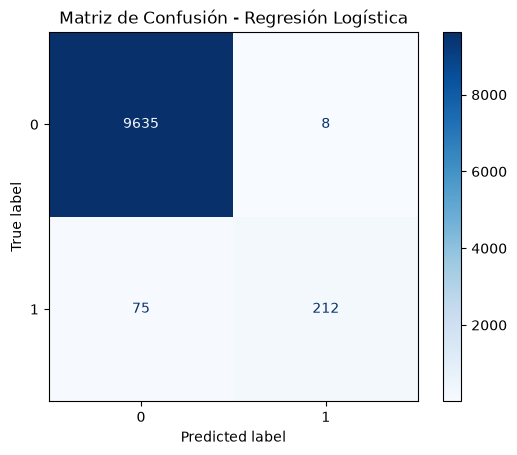

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(
    cmap="Blues"
)

plt.title(
    "Matriz de Confusión - Regresión Logística"
)

plt.show()

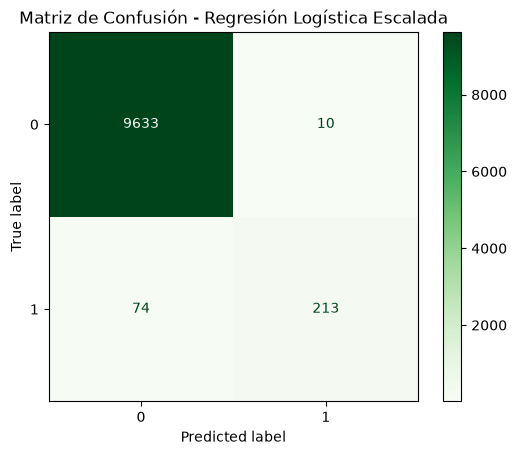

In [25]:
cm_scaled = confusion_matrix(
    y_test_cls,
    pred_cls_scaled
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_scaled
)

disp.plot(
    cmap="Greens"
)

plt.title(
    "Matriz de Confusión - Regresión Logística Escalada"
)

plt.show()

### Interpretación

La matriz de confusión permite visualizar la cantidad de observaciones clasificadas correctamente e incorrectamente.

Los valores de la diagonal principal representan las predicciones correctas, mientras que los valores fuera de la diagonal corresponden a errores de clasificación.

Dado que el Accuracy obtenido es superior al 99%, la mayoría de las observaciones fueron clasificadas correctamente por el modelo.

## Conclusión General

Se entrenaron dos modelos de Machine Learning utilizando los datasets proporcionados.

Para la Regresión Lineal se utilizó la variable salary_in_usd como objetivo. El modelo obtuvo un R² cercano a 0.18, lo que indica que existe capacidad predictiva, aunque todavía hay una parte importante de la variación salarial que no es explicada por las variables utilizadas.

Para la Regresión Logística se utilizó la variable STATUS como objetivo. El modelo logró un Accuracy superior al 99%, mostrando una excelente capacidad para clasificar correctamente el estado de los empleados.

Finalmente, se compararon los resultados antes y después de aplicar StandardScaler. En ambos modelos las diferencias fueron mínimas, lo que indica que el escalamiento no tuvo un impacto significativo en el desempeño para estos conjuntos de datos.